In [1]:
import pandas as pd

df = pd.read_csv("transaction_dataset.csv")
df.head(), df.describe()

(   Unnamed: 0  Index                                     Address  FLAG  \
 0           0      1  0x00009277775ac7d0d59eaad8fee3d10ac6c805e8     0   
 1           1      2  0x0002b44ddb1476db43c868bd494422ee4c136fed     0   
 2           2      3  0x0002bda54cb772d040f779e88eb453cac0daa244     0   
 3           3      4  0x00038e6ba2fd5c09aedb96697c8d7b8fa6632e5e     0   
 4           4      5  0x00062d1dd1afb6fb02540ddad9cdebfe568e0d89     0   
 
    Avg min between sent tnx  Avg min between received tnx  \
 0                    844.26                       1093.71   
 1                  12709.07                       2958.44   
 2                 246194.54                       2434.02   
 3                  10219.60                      15785.09   
 4                     36.61                      10707.77   
 
    Time Diff between first and last (Mins)  Sent tnx  Received Tnx  \
 0                                704785.63       721            89   
 1                              

In [2]:
# Data Preprocessing
# Check for missing values and data types
missing_values = df.isnull().sum()
data_types = df.dtypes

# Drop irrelevant columns (like index columns)
df_cleaned = df.drop(columns=['Unnamed: 0', 'Index'])

# Summary of the dataset after initial cleaning and checking for missing values
missing_values, data_types, df_cleaned.head()

(Unnamed: 0                                                 0
 Index                                                      0
 Address                                                    0
 FLAG                                                       0
 Avg min between sent tnx                                   0
 Avg min between received tnx                               0
 Time Diff between first and last (Mins)                    0
 Sent tnx                                                   0
 Received Tnx                                               0
 Number of Created Contracts                                0
 Unique Received From Addresses                             0
 Unique Sent To Addresses                                   0
 min value received                                         0
 max value received                                         0
 avg val received                                           0
 min val sent                                               0
 max val

In [3]:
# Handle Missing Values/Feature Scaling:

# Imputing missing values with 0, assuming that missing ERC20 values indicate no transactions
df_cleaned.fillna(0, inplace=True)

# Feature scaling using Min-Max normalization for the relevant numerical columns
from sklearn.preprocessing import MinMaxScaler

# Selecting numeric columns for scaling
numeric_cols = df_cleaned.select_dtypes(include=['float64', 'int64']).columns

scaler = MinMaxScaler()
df_cleaned[numeric_cols] = scaler.fit_transform(df_cleaned[numeric_cols])

# Displaying the updated dataset after imputation and scaling
df_cleaned.head()

,Address,FLAG,Avg min between sent tnx,Avg min between received tnx,Time Diff between first and last (Mins),Sent tnx,Received Tnx,Number of Created Contracts,Unique Received From Addresses,Unique Sent To Addresses,...,ERC20 min val sent,ERC20 max val sent,ERC20 avg val sent,ERC20 min val sent contract,ERC20 max val sent contract,ERC20 avg val sent contract,ERC20 uniq sent token name,ERC20 uniq rec token name,ERC20 most sent token type,ERC20_most_rec_token_type
0,0x00009277775ac7d0d59eaad8fee3d10ac6c805e8,0.0,0.001962,0.002268,0.360530,0.0721,0.0089,0.0000,0.0040,0.012706,...,0.000000e+00,1.502768e-04,4.840458e-06,0.0,0.0,0.0,0.183099,0.077341,Cofoundit,Numeraire
1,0x0002b44ddb1476db43c868bd494422ee4c136fed,0.0,0.029536,0.006136,0.623173,0.0094,0.0008,0.0000,0.0005,0.001507,...,2.260809e-08,2.018579e-11,4.026549e-11,0.0,0.0,0.0,0.004695,0.009498,Livepeer Token,Livepeer Token
2,0x0002bda54cb772d040f779e88eb453cac0daa244,0.0,0.572163,0.005048,0.264330,0.0002,0.0010,0.0000,0.0010,0.000215,...,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000,0.010855,0,XENON
3,0x00038e6ba2fd5c09aedb96697c8d7b8fa6632e5e,0.0,0.023751,0.032737,0.203368,0.0025,0.0009,0.0000,0.0007,0.001400,...,1.000000e-06,8.061813e-08,6.775142e-08,0.0,0.0,0.0,0.004695,0.014925,Raiden,XENON
4,0x00062d1dd1afb6fb02540ddad9cdebfe568e0d89,0.0,0.000085,0.022207,0.195652,0.4598,0.0020,0.0001,0.0007,0.002046,...,0.000000e+00,4.017857e-07,2.444747e-07,0.0,0.0,0.0,0.028169,0.036635,StatusNetwork,EOS


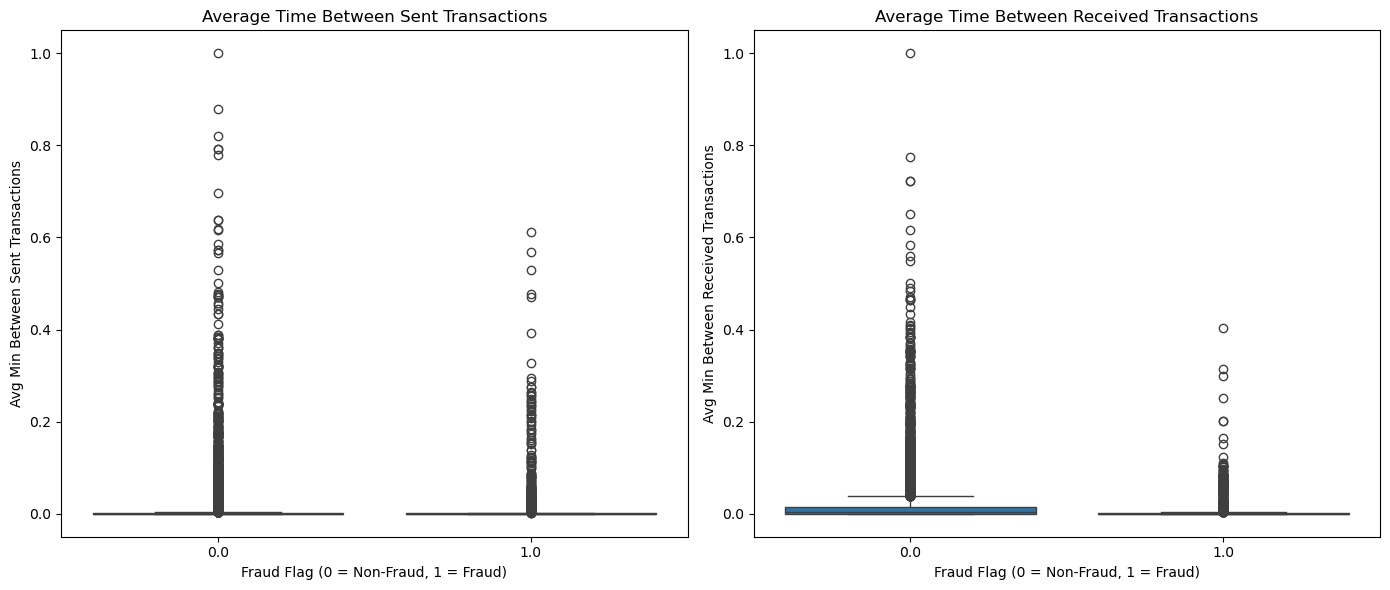

In [4]:
# Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns
# Analyze patterns for fraudulent vs. non-fraudulent transactions based on different of features

# Compare 'Avg min between sent tnx' and 'Avg min between received tnx' for fraudulent and non-fraudulent transactions
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(x='FLAG', y='Avg min between sent tnx', data=df_cleaned, ax=ax[0])
ax[0].set_title('Average Time Between Sent Transactions')
ax[0].set_xlabel('Fraud Flag (0 = Non-Fraud, 1 = Fraud)')
ax[0].set_ylabel('Avg Min Between Sent Transactions')

sns.boxplot(x='FLAG', y='Avg min between received tnx', data=df_cleaned, ax=ax[1])
ax[1].set_title('Average Time Between Received Transactions')
ax[1].set_xlabel('Fraud Flag (0 = Non-Fraud, 1 = Fraud)')
ax[1].set_ylabel('Avg Min Between Received Transactions')

plt.tight_layout()
plt.show()

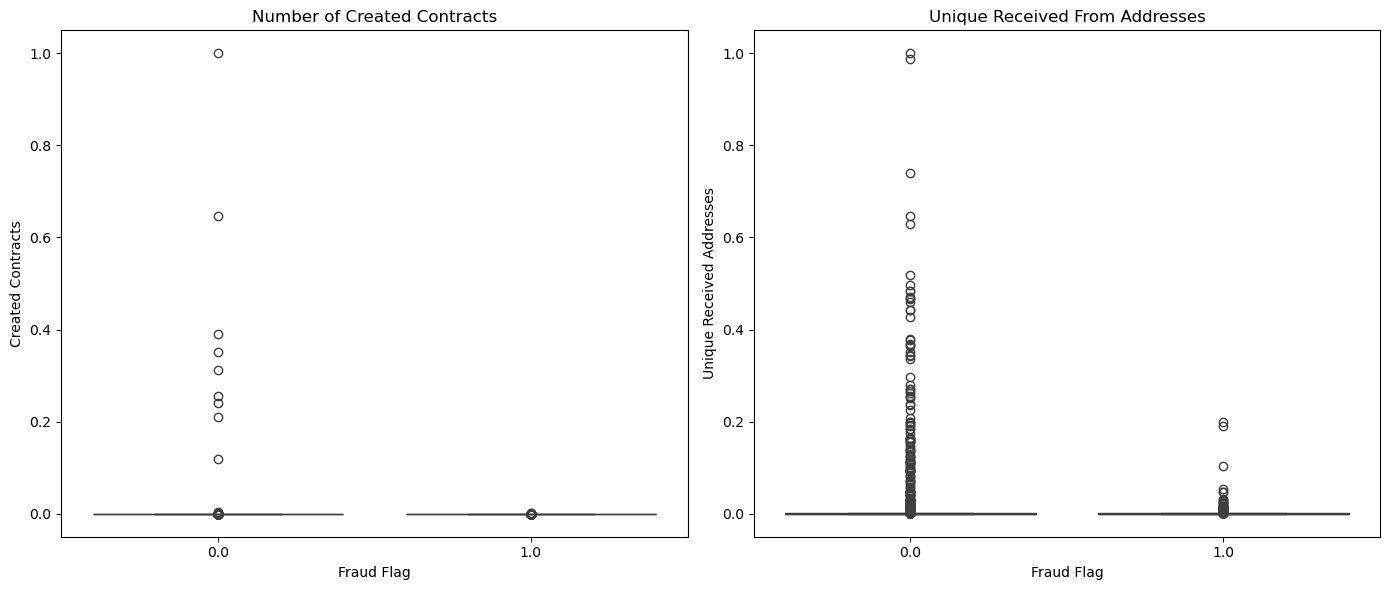

In [5]:
# Number of created contracts and unique addresses comparison for fraud vs non-fraud
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(x='FLAG', y='Number of Created Contracts', data=df_cleaned, ax=ax[0])
ax[0].set_title('Number of Created Contracts')
ax[0].set_xlabel('Fraud Flag')
ax[0].set_ylabel('Created Contracts')

sns.boxplot(x='FLAG', y='Unique Received From Addresses', data=df_cleaned, ax=ax[1])
ax[1].set_title('Unique Received From Addresses')
ax[1].set_xlabel('Fraud Flag')
ax[1].set_ylabel('Unique Received Addresses')

plt.tight_layout()
plt.show()

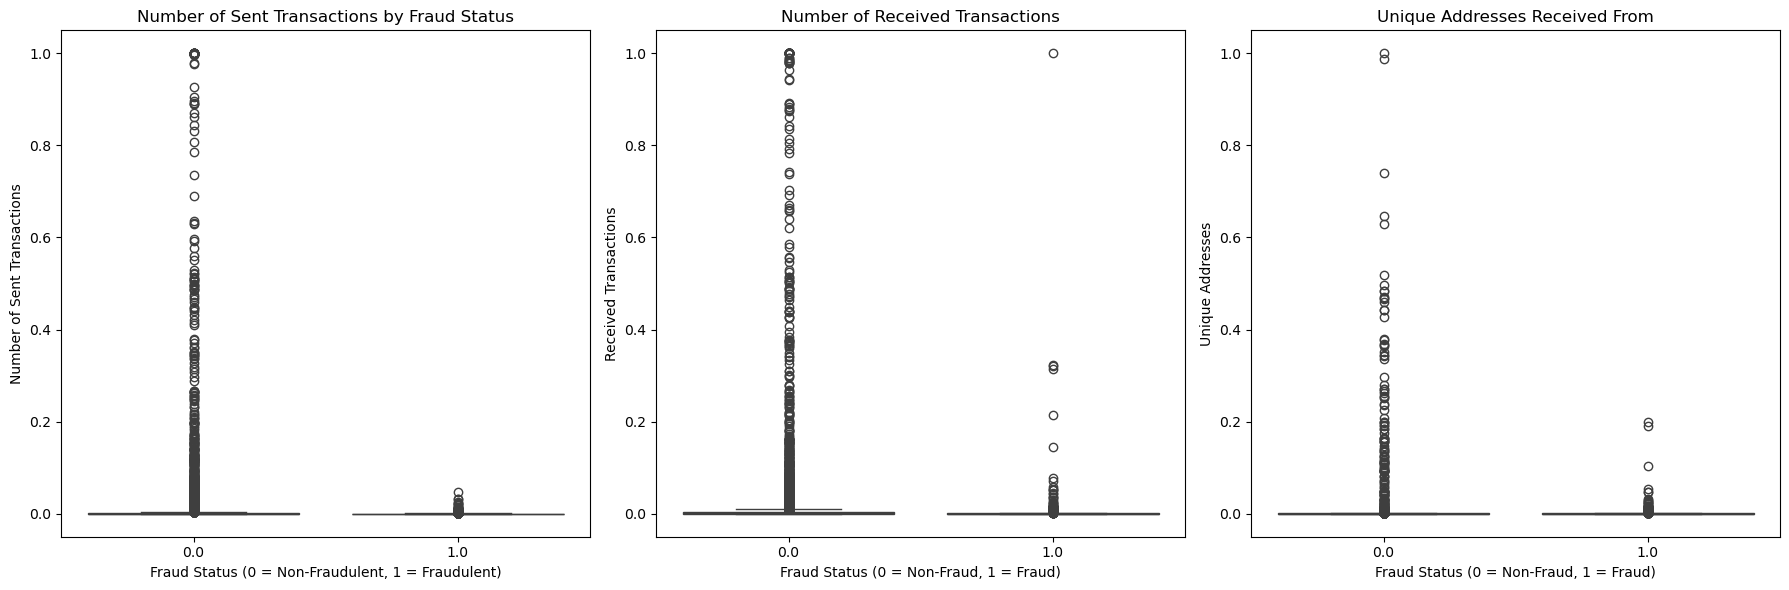

In [6]:
# Compare transaction activity by fraud status
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

sns.boxplot(x='FLAG', y='Sent tnx', data=df_cleaned, ax=ax[0])
ax[0].set_title('Number of Sent Transactions by Fraud Status')
ax[0].set_xlabel('Fraud Status (0 = Non-Fraudulent, 1 = Fraudulent)')
ax[0].set_ylabel('Number of Sent Transactions')

sns.boxplot(x='FLAG', y='Received Tnx', data=df_cleaned, ax=ax[1])
ax[1].set_title('Number of Received Transactions')
ax[1].set_xlabel('Fraud Status (0 = Non-Fraud, 1 = Fraud)')
ax[1].set_ylabel('Received Transactions')

sns.boxplot(x='FLAG', y='Unique Received From Addresses', data=df_cleaned, ax=ax[2])
ax[2].set_title('Unique Addresses Received From')
ax[2].set_xlabel('Fraud Status (0 = Non-Fraud, 1 = Fraud)')
ax[2].set_ylabel('Unique Addresses')

plt.tight_layout()
plt.show()

In [7]:
# Checking the correct column names to avoid column name mismatch issues
df_cleaned.columns

Index(['Address', 'FLAG', 'Avg min between sent tnx',
       'Avg min between received tnx',
       'Time Diff between first and last (Mins)', 'Sent tnx', 'Received Tnx',
       'Number of Created Contracts', 'Unique Received From Addresses',
       'Unique Sent To Addresses', 'min value received', 'max value received ',
       'avg val received', 'min val sent', 'max val sent', 'avg val sent',
       'min value sent to contract', 'max val sent to contract',
       'avg value sent to contract',
       'total transactions (including tnx to create contract',
       'total Ether sent', 'total ether received',
       'total ether sent contracts', 'total ether balance',
       ' Total ERC20 tnxs', ' ERC20 total Ether received',
       ' ERC20 total ether sent', ' ERC20 total Ether sent contract',
       ' ERC20 uniq sent addr', ' ERC20 uniq rec addr',
       ' ERC20 uniq sent addr.1', ' ERC20 uniq rec contract addr',
       ' ERC20 avg time between sent tnx', ' ERC20 avg time between rec tn

In [8]:
df_cleaned.columns = df_cleaned.columns.str.strip()
df_cleaned.columns

Index(['Address', 'FLAG', 'Avg min between sent tnx',
       'Avg min between received tnx',
       'Time Diff between first and last (Mins)', 'Sent tnx', 'Received Tnx',
       'Number of Created Contracts', 'Unique Received From Addresses',
       'Unique Sent To Addresses', 'min value received', 'max value received',
       'avg val received', 'min val sent', 'max val sent', 'avg val sent',
       'min value sent to contract', 'max val sent to contract',
       'avg value sent to contract',
       'total transactions (including tnx to create contract',
       'total Ether sent', 'total ether received',
       'total ether sent contracts', 'total ether balance', 'Total ERC20 tnxs',
       'ERC20 total Ether received', 'ERC20 total ether sent',
       'ERC20 total Ether sent contract', 'ERC20 uniq sent addr',
       'ERC20 uniq rec addr', 'ERC20 uniq sent addr.1',
       'ERC20 uniq rec contract addr', 'ERC20 avg time between sent tnx',
       'ERC20 avg time between rec tnx', 'ERC20 

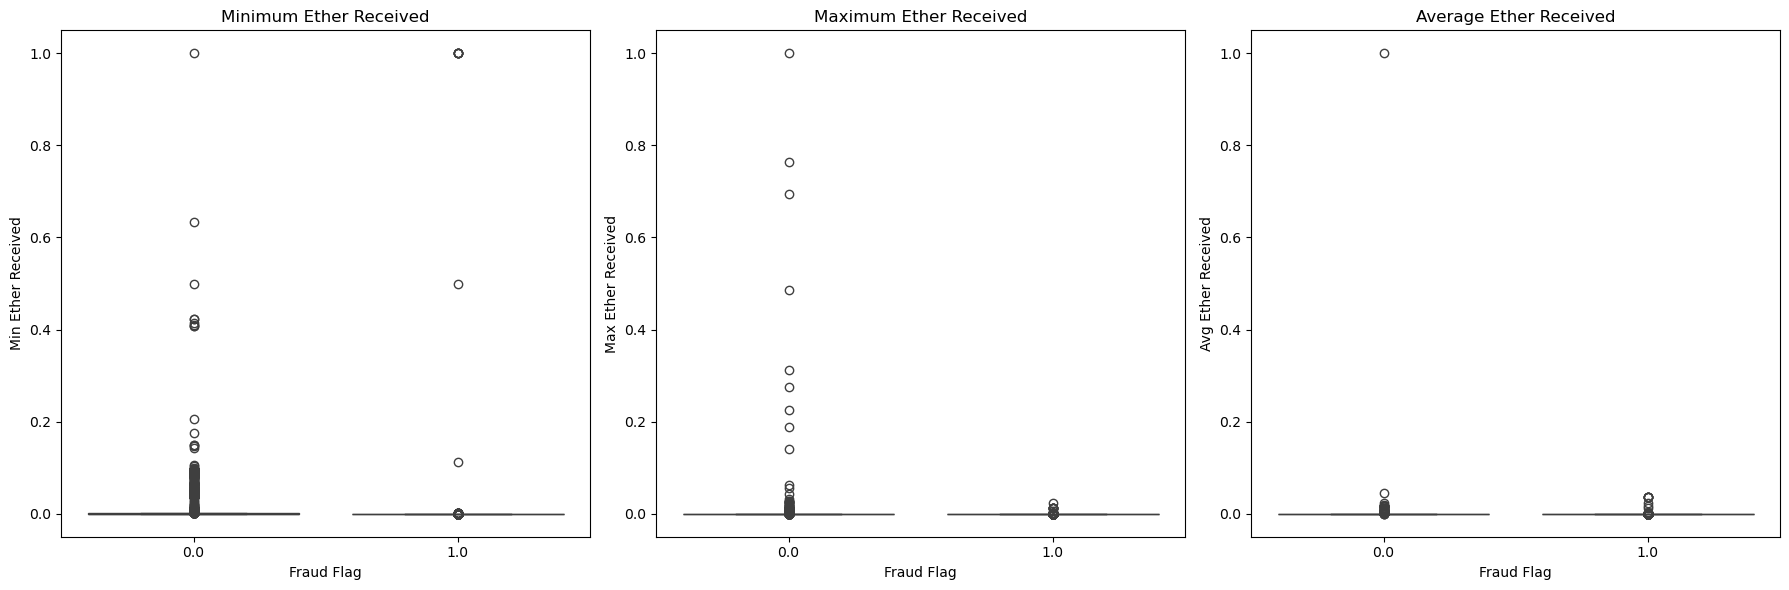

In [9]:
# Ether Value statistics (Min, Max, and Average) for fraudulent vs non-fraudulent transactions
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

sns.boxplot(x='FLAG', y='min value received', data=df_cleaned, ax=ax[0])
ax[0].set_title('Minimum Ether Received')
ax[0].set_xlabel('Fraud Flag')
ax[0].set_ylabel('Min Ether Received')

sns.boxplot(x='FLAG', y='max value received', data=df_cleaned, ax=ax[1])
ax[1].set_title('Maximum Ether Received')
ax[1].set_xlabel('Fraud Flag')
ax[1].set_ylabel('Max Ether Received')

sns.boxplot(x='FLAG', y='avg val received', data=df_cleaned, ax=ax[2])
ax[2].set_title('Average Ether Received')
ax[2].set_xlabel('Fraud Flag')
ax[2].set_ylabel('Avg Ether Received')

plt.tight_layout()
plt.show()

In [10]:
# Selecting only numeric columns for correlation analysis
numeric_columns = df_cleaned.select_dtypes(include=['float64', 'int64'])

# Performing correlation analysis
correlation_matrix = numeric_columns.corr()

# Extracting the correlations with the target variable 'FLAG'
corr_with_flag = correlation_matrix['FLAG'].sort_values(ascending=False)

# Displaying the top and bottom correlations
corr_with_flag.head(15), corr_with_flag.tail(15)

(FLAG                               1.000000
 ERC20 min val sent                 0.019023
 ERC20 avg val sent                 0.018835
 ERC20 max val sent                 0.018770
 ERC20 total ether sent             0.018428
 ERC20 total Ether sent contract    0.008127
 min val sent                       0.006626
 ERC20 min val rec                  0.004434
 ERC20 avg val rec                  0.003132
 total ether balance               -0.003229
 ERC20 max val rec                 -0.005510
 ERC20 total Ether received        -0.005711
 min value sent to contract        -0.007213
 max val sent to contract          -0.007988
 total ether sent contracts        -0.007988
 Name: FLAG, dtype: float64,
 ERC20 uniq rec contract addr                           -0.061948
 ERC20 uniq rec token name                              -0.062397
 avg val sent                                           -0.063556
 Sent tnx                                               -0.078006
 Received Tnx                   

In [11]:
# Several ERC20 timing features appear to have no data (NaN) and will be excluded from further analysis.

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df_cleaned.drop(columns=['FLAG'])
y = df_cleaned['FLAG']

# Remove columns that contain only missing values
X = X.dropna(axis=1, how='all')

# Convert any non-numeric values in the feature set to numeric, filling non-convertible values with 0
X_cleaned = X.apply(pd.to_numeric, errors='coerce').fillna(0)


# 4. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_cleaned,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Initialize the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=1
)
# Train the Random Forest model
rf_model.fit(X_train, y_train)

# Extracting feature importance
feature_importances = rf_model.feature_importances_

# Creating a DataFrame to display feature importance
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Display the top features
importance_df.head(15)

,Feature,Importance
3,Time Diff between first and last (Mins),0.105125
20,total ether received,0.091177
11,avg val received,0.078291
10,max value received,0.070286
2,Avg min between received tnx,0.068332
7,Unique Received From Addresses,0.062283
19,total Ether sent,0.050280
35,ERC20 min val rec,0.047319
18,total transactions (including tnx to create co...,0.042619
9,min value received,0.040863


In [12]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [13]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

# Extracting feature importance
feature_importances = xgb_model.feature_importances_

# Creating a DataFrame to display feature importance
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Display the top features
importance_df.head(15)

,Feature,Importance
10,max value received,0.194238
20,total ether received,0.104200
35,ERC20 min val rec,0.075193
3,Time Diff between first and last (Mins),0.068849
11,avg val received,0.063260
36,ERC20 max val rec,0.052783
25,ERC20 total ether sent,0.049419
7,Unique Received From Addresses,0.042013
9,min value received,0.035569
2,Avg min between received tnx,0.032008


In [14]:
# cross-validation techniques like stratified k-fold to ensure model performance is evaluated properly across classes.

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Initialize models
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
xgb_model =  XGBClassifier(eval_metric='logloss', scale_pos_weight=10, random_state=42)
logistic_model = LogisticRegression(max_iter=1000, class_weight='balanced')

# Stratified k-fold cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluating models using cross-validation for Random Forest, XGBoost, and Logistic Regression
rf_scores = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring='roc_auc')
xgb_scores =  cross_val_score(xgb_model, X_train, y_train, cv=cv, scoring='roc_auc')
logistic_scores =  cross_val_score(logistic_model, X_train, y_train, cv=cv, scoring='roc_auc')

# Display the cross-validation ROC AUC scores for each model
rf_scores.mean(), xgb_scores.mean(), logistic_scores.mean()

(0.9866988015980216, 0.9906313491961063, 0.7535489139282203)

In [15]:
# Reducing the number of boosting rounds for XGBoost to speed up training
xgb_model_optimized = XGBClassifier(n_estimators=50, eval_metric='logloss', scale_pos_weight=10, random_state=42)

# Re-running the cross-validation for all models
rf_scores = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring='roc_auc')
xgb_scores = cross_val_score(xgb_model_optimized, X_train, y_train, cv=cv, scoring='roc_auc')
logistic_scores = cross_val_score(logistic_model, X_train, y_train, cv=cv, scoring='roc_auc')

# Displaying the mean ROC AUC scores for each model
rf_mean_auc = rf_scores.mean()
xgb_mean_auc = xgb_scores.mean()
logistic_mean_auc = logistic_scores.mean()

rf_mean_auc, xgb_mean_auc, logistic_mean_auc

(0.9866988015980216, 0.9901579410194016, 0.7535489139282203)

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Define the models
models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model_optimized,
    "Logistic Regression": logistic_model
}

# Store evaluation results
results = []

# Train and evaluate each model
for name, model in models.items():
    
    # Train the model
    model.fit(X_train, y_train)

    # Predict class labels
    y_pred = model.predict(X_test)

    # Predict fraud probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    auc = roc_auc_score(y_test, y_prob)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Save results
    results.append({
        "Model": name,
        "AUC-ROC": auc,
        "Precision": precision,
        "Recall": recall, 
        "F1-score": f1
    })

    # Display individual classification report
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Non-Fraud", "Fraud"],
        zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


Random Forest
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.99      0.97      1533
       Fraud       0.97      0.83      0.90       436

    accuracy                           0.96      1969
   macro avg       0.96      0.91      0.93      1969
weighted avg       0.96      0.96      0.96      1969

Confusion Matrix:
[[1521   12]
 [  72  364]]

XGBoost
              precision    recall  f1-score   support

   Non-Fraud       0.98      0.98      0.98      1533
       Fraud       0.92      0.92      0.92       436

    accuracy                           0.96      1969
   macro avg       0.95      0.95      0.95      1969
weighted avg       0.96      0.96      0.96      1969

Confusion Matrix:
[[1497   36]
 [  34  402]]

Logistic Regression
              precision    recall  f1-score   support

   Non-Fraud       0.92      0.49      0.64      1533
       Fraud       0.32      0.85      0.47       436

    accuracy                           0.57    

In [17]:
# Create a comparison table
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))


MODEL PERFORMANCE COMPARISON


,Model,AUC-ROC,Precision,Recall,F1-score
0,Random Forest,0.9876,0.9681,0.8349,0.8966
1,XGBoost,0.9906,0.9178,0.9220,0.9199
2,Logistic Regression,0.7502,0.3223,0.8463,0.4668


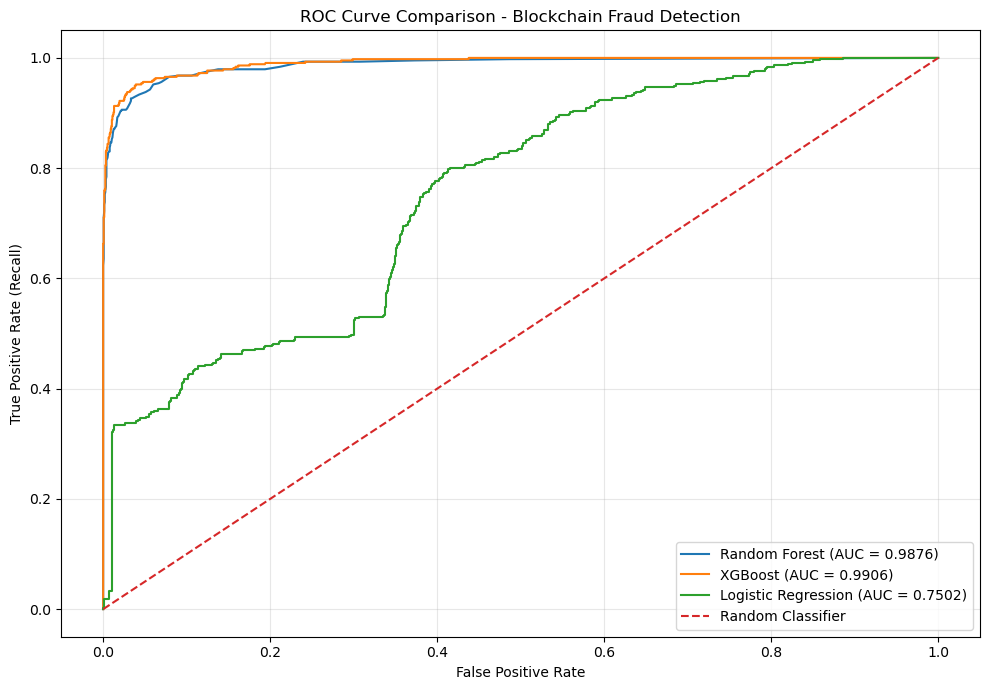

In [18]:
# Generate the AUC-ROC curves
plt.figure(figsize=(10, 7))

for name, model in models.items():

    # Get predicted probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # Calculate AUC
    auc = roc_auc_score(y_test, y_prob)

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

# Plot random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

    
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison - Blockchain Fraud Detection")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

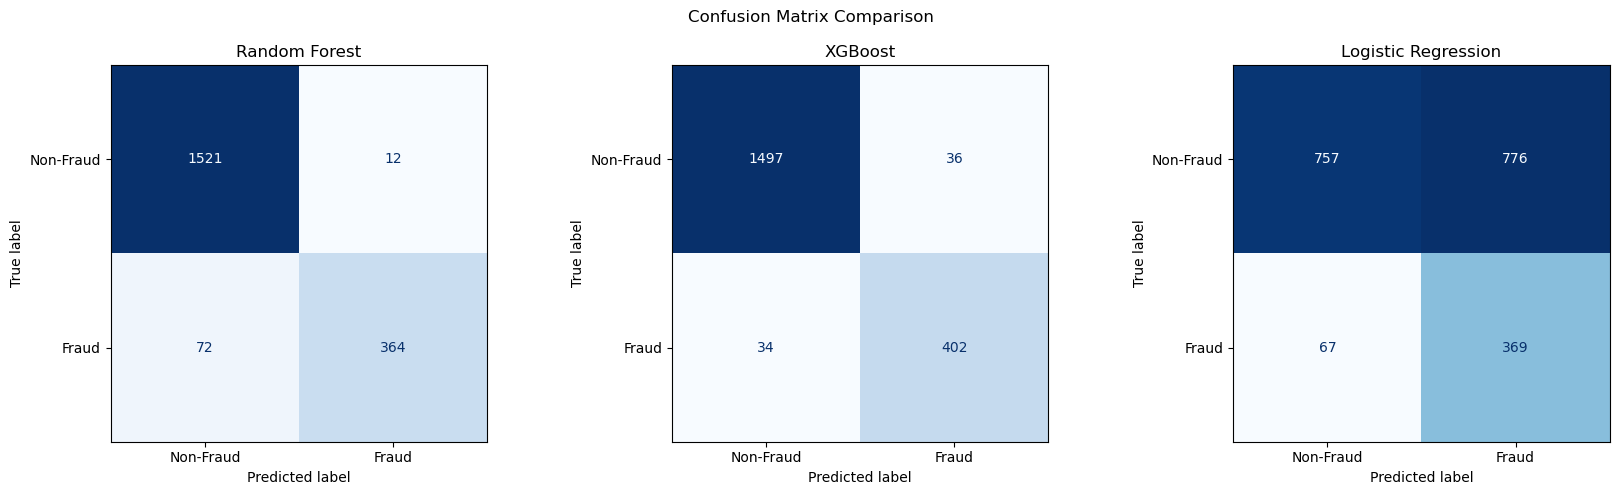

In [19]:
# Generate confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Fraud", "Fraud"]
    )
    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

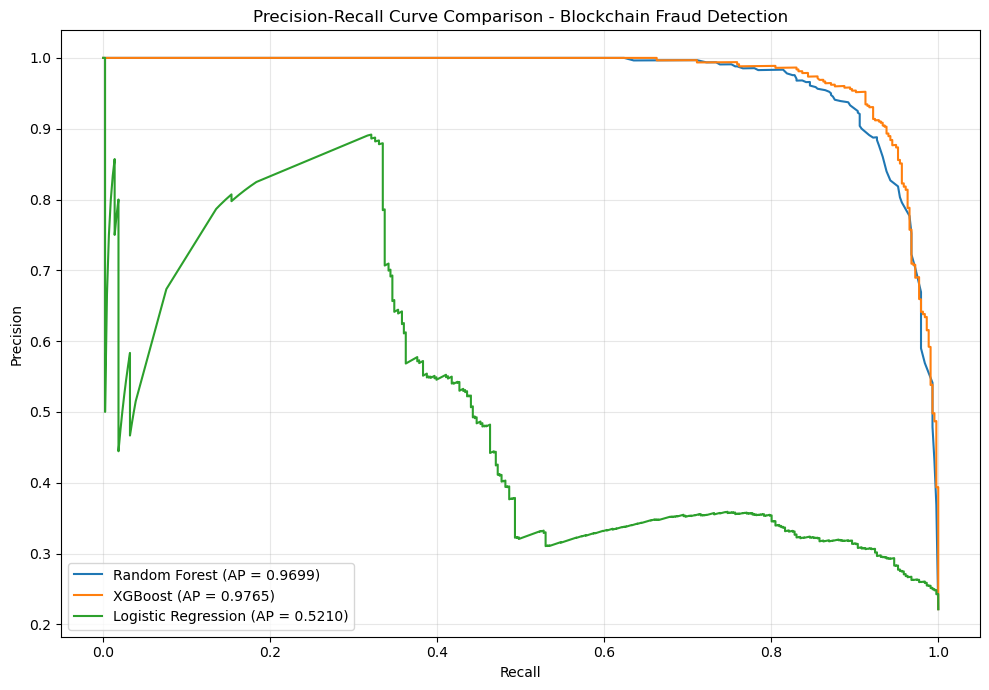

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for name, model in models.items():

    # Get fraud probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate precision and recall
    precision, recall, thresholds = precision_recall_curve(
        y_test, y_prob
    )

    # Calculate Average Precision
    ap = average_precision_score(y_test, y_prob)

    # Plot the curve
    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.4f})"
    )

# Add labels and formatting
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison - Blockchain Fraud Detection")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# Fraud Prevention Strategy:

# Train the model and establish a fraud detection threshold
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import(
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    average_precision_score
)
# Select XGBoost as the leading model
fraud_model = clone(xgb_model_optimized)

# Split training data into training and validation sets
X_subtrain, X_valid, y_subtrain, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)
# Train on the smaller training subset
fraud_model.fit(X_subtrain, y_subtrain)

# Calculate fraud probabilities on validation data
valid_prob = fraud_model.predict_proba(X_valid)[:, 1]

# Calculate precision-recall values
precision, recall, threshold = precision_recall_curve(
    y_valid, valid_prob
)

# Select a threshold that achieves at least 95% recall
target_recall = 0.95

# The final precision and recall values have no matching threshold
valid_thresholds = thresholds
valid_precision = precision[:-1]
valid_recall = recall[:-1]

eligible = np.where(valid_recall >= target_recall)[0]


if len(eligible) > 0:
    # Among thresholds meeting target recall, select highest precision
    best_index = eligible[
        np.argmax(valid_precision[eligible])
    ]
    fraud_threshold = valid_thresholds[best_index]
else:
    # Fallback: select the threshold with the highest validation recall
    best_index = np.argmax(valid_recall)
    fraud_threshold = valid_thresholds[best_index]

print("Selected fraud detection threshold:", round(fraud_threshold, 4))
print("Validation recall:", round(valid_recall[best_index], 4))
print("Validation precision:", round(valid_precision[best_index], 4))

Selected fraud detection threshold: 0.567
Validation recall: 0.9542
Validation precision: 0.8083


In [22]:
# Refit the selected model using all training data
fraud_model.fit(X_train, y_train)

# Score transactions in the test dataset
test_prob = fraud_model.predict_proba(X_test)[:, 1]

# Classify transactions using the selected threshold
test_pred = (test_prob >= fraud_threshold).astype(int)

# Evaluate final test performance
print("\nFRAUD DETECTION PERFORMANCE")
print("Average Precision:",
      round(average_precision_score(y_test, test_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Non-Fraud", "Fraud"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))


FRAUD DETECTION PERFORMANCE
Average Precision: 0.9765

Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.98      0.98      0.98      1533
       Fraud       0.93      0.92      0.93       436

    accuracy                           0.97      1969
   macro avg       0.95      0.95      0.95      1969
weighted avg       0.97      0.97      0.97      1969


Confusion Matrix:
[[1503   30]
 [  34  402]]


In [25]:
# Blockchain Fraud Transaction Monitoring System
import numpy as np
import pandas as pd
from IPython.display import display

# Create a transaction monitoring table
fraud_monitoring = X_test.copy()

# Add actual labels and predicted fraud probabilities
fraud_monitoring["Actual_Fraud"] = y_test.values
fraud_monitoring["Fraud_Probability"] = test_prob
fraud_monitoring["Predicted_Fraud"] = test_pred

# Define operational risk categories
high_risk_threshold = max(fraud_threshold, 0.80)

fraud_monitoring["Risk_Level"] = np.select(
    [
        fraud_monitoring["Fraud_Probability"] >= high_risk_threshold,
        fraud_monitoring["Fraud_Probability"] >= fraud_threshold
    ],
    [
        "HIGH RISK",
        "MEDIUM RISK"
    ],
    default="LOW RISK"
)

# Recommend preventive actions
fraud_monitoring["Recommended_Action"] = np.select(
    [
        fraud_monitoring["Risk_Level"] == "HIGH RISK",
        fraud_monitoring["Risk_Level"] == "MEDIUM RISK"
    ],
    [
        "Temporarily hold and investigate",
        "Flag for additional verification"
    ],
    default="Allow, subject to routine monitoring"
)

# Sort transactions by highest fraud probability
fraud_monitoring = fraud_monitoring.sort_values(
    by="Fraud_Probability",
    ascending=False
)

# Display the highest-risk transactions
display(
    fraud_monitoring[
        [
            "Actual_Fraud",
            "Fraud_Probability",
            "Predicted_Fraud",
            "Risk_Level",
            "Recommended_Action"
        ]
    ].head(20).round(4)
)

,Actual_Fraud,Fraud_Probability,Predicted_Fraud,Risk_Level,Recommended_Action
9261,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
7682,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
7999,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
9660,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
8736,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
9092,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
9383,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
8221,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
8289,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate
9269,1.0,1.0,1,HIGH RISK,Temporarily hold and investigate


In [27]:
# Monitor unusual transaction behaviour

# Candidate behavioural features
behaviour_features = [
    "Avg min between sent tnx",
    "Avg min between received tnx",
    "Number of Created Contracts",
    "Unique Received From Addresses",
    "transaction_velocity_24h",
    "unusual_pattern_score"
]
# Keep only features available in your dataset
available_features = [
    col for col in behaviour_features
    if col in X_train.columns
]
# Calculate the 99th percentile using training data
behaviour_limits = X_train[available_features].quantile(0.99)

# Flag unusually high behavioural values
for col in available_features:
    fraud_monitoring[f"{col}_Anomaly"] = (
         fraud_monitoring[col] > behaviour_limits[col]
    )
# Count unusual behavioural indicators
anomaly_columns = [
    f"{col}_Anomaly" for col in available_features
]
if anomaly_columns:
    fraud_monitoring["Behaviour_Anomaly_Count"] = (
        fraud_monitoring[anomaly_columns].sum(axis=1)
    )
    fraud_monitoring["Behaviour_Flag"] = np.where(
        fraud_monitoring["Behaviour_Anomaly_Count"] > 0,
        "Unusual Behaviour Detected",
        "No Unusual Behaviour Detected"
    )
display(fraud_monitoring.head(10))

,Address,Avg min between sent tnx,Avg min between received tnx,Time Diff between first and last (Mins),Sent tnx,Received Tnx,Number of Created Contracts,Unique Received From Addresses,Unique Sent To Addresses,min value received,...,Fraud_Probability,Predicted_Fraud,Risk_Level,Recommended_Action,Avg min between sent tnx_Anomaly,Avg min between received tnx_Anomaly,Number of Created Contracts_Anomaly,Unique Received From Addresses_Anomaly,Behaviour_Anomaly_Count,Behaviour_Flag
9261,0.0,0.0,0.000183,0.007160,0.0001,0.0019,0.0,0.0017,0.000108,0.000000e+00,...,0.999982,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
7682,0.0,0.0,0.000559,0.008228,0.0001,0.0021,0.0,0.0021,0.000108,3.000000e-08,...,0.999980,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
7999,0.0,0.0,0.000328,0.004033,0.0001,0.0007,0.0,0.0005,0.000108,4.900000e-05,...,0.999979,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
9660,0.0,0.0,0.000095,0.001131,0.0001,0.0007,0.0,0.0007,0.000108,4.400000e-06,...,0.999978,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
8736,0.0,0.0,0.001445,0.008043,0.0001,0.0014,0.0,0.0014,0.000108,5.196000e-07,...,0.999977,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
9092,0.0,0.0,0.000979,0.001455,0.0001,0.0005,0.0,0.0004,0.000108,5.000000e-05,...,0.999975,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
9383,0.0,0.0,0.000231,0.011938,0.0001,0.0025,0.0,0.0020,0.000108,0.000000e+00,...,0.999975,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
8221,0.0,0.0,0.000791,0.004132,0.0001,0.0011,0.0,0.0007,0.000108,3.291180e-05,...,0.999967,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
8289,0.0,0.0,0.000387,0.001710,0.0001,0.0015,0.0,0.0014,0.000108,3.699200e-06,...,0.999967,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected
9269,0.0,0.0,0.002172,0.015524,0.0001,0.0023,0.0,0.0023,0.000108,0.000000e+00,...,0.999961,1,HIGH RISK,Temporarily hold and investigate,False,False,False,False,0,No Unusual Behaviour Detected


In [34]:
# Summarize the prevention strategy

# Summarize transactions by risk level
risk_summary = (
    fraud_monitoring["Risk_Level"]
    .value_counts()
    .reindex(["HIGH RISK", "MEDIUM RISK", "LOW RISK"], fill_value=0)
     .reset_index()
)
risk_summary.columns = ["Risk Level", "Number of Transactions"]

# Calculate total transactions
total_transactions = risk_summary[
    "Number of Transactions"
].sum()

# Calculate percentage distribution
risk_summary["Percentage"] = (
    risk_summary["Number of Transactions"]
    / total_transactions * 100
).round(2)

print("BLOCKCHAIN FRAUD PREVENTION SUMMARY")
display(risk_summary)

BLOCKCHAIN FRAUD PREVENTION SUMMARY


,Risk Level,Number of Transactions,Percentage
0,HIGH RISK,396,20.11
1,MEDIUM RISK,36,1.83
2,LOW RISK,1537,78.06


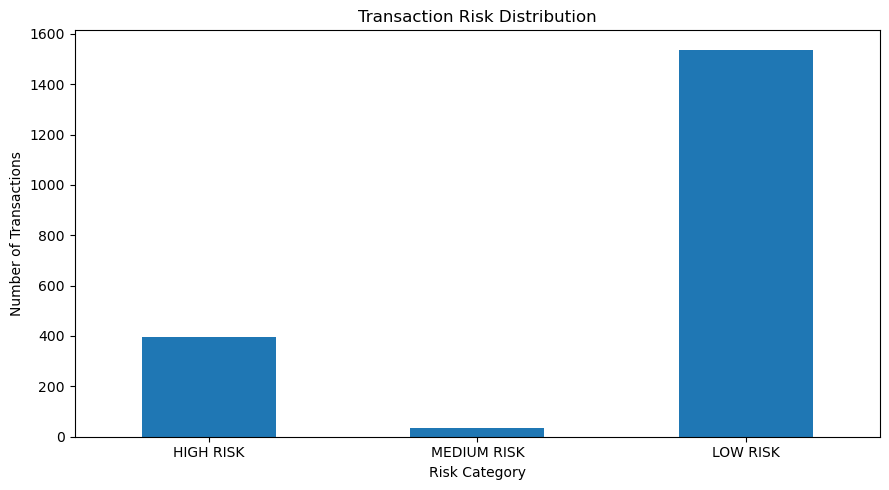

In [32]:
# Plot the risk distribution
risk_summary.plot(
    x="Risk Level",
    y="Number of Transactions",
    kind="bar",
    legend=False,
    figsize=(9, 5),
    rot=0
)
plt.title("Transaction Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

"""
This project investigated fraudulent and non-fraudulent Ethereum transactions and developed a predictive framework for cryptocurrency fraud detection and prevention. Through data preprocessing, statistical analysis, boxplots, correlation analysis and examination of transaction behavioural characteristics, including transaction frequency, average intervals between sent and received transactions, Ether transfer values, smart contract creation and unique receiving addresses, the analysis identified variations in transaction patterns and potential indicators of suspicious activity. Comparative evaluation of Random Forest, XGBoost and Logistic Regression demonstrated the superior predictive performance of ensemble-based models, with XGBoost achieving a cross-validation ROC-AUC of approximately 0.9906 and the highest Average Precision of 0.9765, compared with Random Forest (0.9699 Average Precision) and Logistic Regression (0.5210). Validation-based classification threshold selection and final testing of 1,969 transactions, the optimized XGBoost model achieved approximately 97% accuracy, 93% fraud precision, 92% fraud recall and a fraud F1-score of 0.93, correctly identifying 402 fraudulent transactions and 1,503 legitimate transactions, while recording 34 false negatives and 30 false positives. These findings demonstrate the potential of predictive analytics to distinguish suspicious transaction behaviour, prioritize fraud investigation and support evidence-based risk management. XGBoost should be considered the leading model for further development, supported by continuous threshold optimization, improved data preprocessing, behavioural anomaly detection, explainable AI techniques such as SHAP and chronological validation to assess performance against emerging fraud patterns. Integration of **blockchain analytics and API-based applications** could facilitate near-real-time risk assessment, while continuous model monitoring, data privacy, transparency and responsible intervention would strengthen operational reliability. Finally, the project demonstrates how machine learning and predictive modelling can transform Ethereum transaction data into actionable intelligence, providing a foundation for a scalable, explainable and proactive blockchain fraud detection and prevention system.
"""